In [1]:
import pytest
import numpy as np
import itertools

from nlr_ghe_screen.clustering.milp import solve_cluster
from load_scenarios import (
    solve_scenario,
    constant_profile,
    random_loads,
    scenario_perfect_cancellation,
    scenario_all_cooling,
    scenario_all_heating,
    scenario_phase_shifted_sinusoids,
    scenario_staggered_spikes,
    scenario_random
)


In [2]:
# ---------------------------------------------------------------------------
# Scenarios
# ---------------------------------------------------------------------------
import random

TOL = dict(rel=1e-3, abs=1e-3)

DETERMINISTIC = [
    scenario_perfect_cancellation(),
    scenario_all_heating(),
    scenario_all_cooling(),
    scenario_phase_shifted_sinusoids(),
    scenario_staggered_spikes(),
]

RANDOM = [
    scenario_random(seed=s, seed_idx=s, k_min=2 + (s % 3), heating_fraction=hf)
    for s, hf in zip(range(7), [0.5, 0.5, 0.3, 0.7, 0.5, 0.5, 0.4])
]

ALL_SCENARIOS = DETERMINISTIC + RANDOM
KNOWN = [s for s in ALL_SCENARIOS if s.expected_peak is not None]

by_name = lambda s: s.name

In [3]:
# ------------- Helper Functions ------------- 
def approx_imbalance(expected, loads):
    """Tolerance scaled to Q_ref = sum|A_i|, since the solver's objective is q / Q_ref and
    CPLEX's absolute MIP gap applies to that scaled value."""
    q_ref = max(np.abs(annual_energy(loads)).sum(), 1e-9)

    return pytest.approx(expected, rel=1e-3, abs=max(1e-4 * q_ref, 1e-6))

def annual_energy(loads):
    l = np.asarray(loads, dtype=float)
    return l.sum(axis=1)

def brute_force_min_imbalance(loads, seed_idx, k_min):
    """
    Enumerate every subset containing the seed with size >= k_min
    """
    A = annual_energy(loads)
    others = [i for i in range(len(A)) if i != seed_idx]
    best_q, best_set = np.inf, None

    for r in range(max(k_min - 1, 0), len(others) + 1):
        for combo in itertools.combinations(others, r):
            sel = [seed_idx, *combo]
            q = float(abs(A[sel].sum()))

            if q < best_q:
                best_q, best_set = q, sorted(sel)

    return best_q, best_set

# -----------------------------------------------

In [4]:
for sc in ALL_SCENARIOS:
    # Check that for all scenarios, the MILP peak matches the brute force peak
    res = solve_scenario(sc, weight_peak=0.0, weight_net=1, weight_distance=0.0)
    expected, _ = brute_force_min_imbalance(sc.loads, sc.seed_idx, sc.k_min)

    print(res['imbalance'], expected)

0.0 0.0
72.0 72.0
72.0 72.0
3.552713678800501e-15 2.8327694488239896e-15
40.0 40.0
4.53266386039817 4.5326638603981735
7.032481807648877 7.032481807648864
9.237542842888963 9.237542842888942
11.471546305907747 11.471546305907736
0.4148900554570538 0.4148900554570787
4.12781390625548 4.127813906255497
0.7925568667663461 0.792556866766347


In [ ]:
import matplotlib.pyplot as plt

sc = RANDOM[3]
res = solve_scenario(sc, weight_peak=0.0, weight_net=1.0, weight_distance=0.0)
selected = res['selected']
expected, best_set = brute_force_min_imbalance(sc.loads, sc.seed_idx, sc.k_min)

Scenario(name='random_s3', loads=array([[  4.31209796,   5.031026  ,   6.29816001,   7.34627689,
          8.37024752,   9.93326915,  11.43636232,  11.70167458,
         12.84753385,  12.2099325 ,  12.08950547,  12.45195719,
         10.97869076,   9.25435293,   8.23026588,   7.38993154,
          6.98785365,   4.47398614,   3.52571689,   3.58471156,
          2.01140388,   2.30158218,   3.28517672,   3.67542962],
       [  0.86754789,   2.84103004,   1.82786006,   1.83397827,
          3.61259589,   4.75833416,   5.18207004,   5.98786143,
          7.78610733,   8.84928567,  10.63804864,  11.02211596,
         11.20500983,  11.92525967,  11.07484997,  10.26108364,
         10.43471012,   9.52774817,   8.00631066,   6.52268097,
          5.91921907,   3.27282938,   4.10721174,   3.23893088],
       [-11.86706834, -12.78829798, -10.56666714, -10.48661469,
        -10.47735196,  -9.56011553,  -6.20546964,  -5.94724933,
         -5.25252113,  -3.62431526,  -4.18882238,  -1.93951985,
     

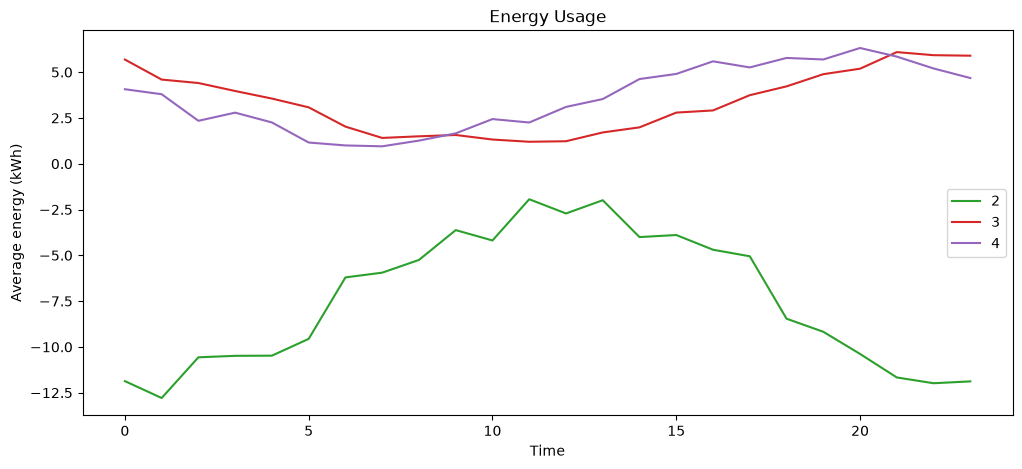

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors  
for i in selected:
    ax.plot(
        list(range(len(sc.loads[0]))),
        sc.loads[i],
        color=colors[i % len(colors)],
        label=i
    )

ax.set_xlabel("Time")
ax.set_ylabel("Average energy (kWh)")
ax.set_title(f"Energy Usage")
ax.legend(title=None)

plt.legend()
plt.show()